# 2ABC: Waterfall and Ridge Plots

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib as mpl
from collections import Counter, defaultdict
import argparse
import sys


def get_canonical_kmer(kmer):
    """
    Get the lexicographically smallest rotation of a k-mer.

    For example, 'GAAGG' and 'AAGGG' both return 'AAGGG'.
    """
    if not kmer:
        return kmer

    # Generate all rotations and return the lexicographically smallest
    rotations = [kmer[i:] + kmer[:i] for i in range(len(kmer))]
    return min(rotations)


def get_all_rotations(kmer):
    """
    Get all rotations of a k-mer.
    """
    return [kmer[i:] + kmer[:i] for i in range(len(kmer))]


def extract_all_kmers(sequences, k_sizes):
    """
    Extract all k-mers of specified sizes from all sequences.

    Args:
        sequences: List of sequences to extract k-mers from
        k_sizes: List of k-mer sizes to extract (e.g., [3, 5, 6])

    Returns a Counter of canonical k-mer frequencies.
    """
    kmer_counts = Counter()

    for seq in sequences:
        if pd.isna(seq) or seq == '':
            continue
        seq = str(seq).upper()

        # Extract k-mers of specified sizes
        for k in k_sizes:
            if k > len(seq):
                continue
            for i in range(len(seq) - k + 1):
                kmer = seq[i:i+k]
                # Convert to canonical form (lexicographically smallest rotation)
                canonical = get_canonical_kmer(kmer)
                kmer_counts[canonical] += 1

    return kmer_counts


def is_perfect_repetition(kmer):
    """
    Check if a k-mer is a perfect repetition of a shorter k-mer.

    For example, 'AAGAAGAAGAAG' is a perfect repetition of 'AAG'.
    Returns (True, base_kmer) if it's a perfect repetition, (False, None) otherwise.
    """
    kmer_len = len(kmer)

    # Try all possible divisor lengths
    for base_len in range(1, kmer_len):
        if kmer_len % base_len == 0:
            # Check if kmer is made of perfect repetitions of the base
            num_reps = kmer_len // base_len
            base = kmer[:base_len]
            if base * num_reps == kmer:
                return True, base

    return False, None


def filter_subsequence_kmers(kmer_counts, sequences):
    """
    Filter out k-mers that only appear as subsequences of other k-mers.

    If k-mer A is a subsequence of k-mer B, and all occurrences of A
    are within occurrences of B, then A is removed.
    Works with canonical k-mers and their rotations.

    Also filters out k-mers that are perfect repetitions of shorter k-mers.
    """
    # Sort k-mers by length (longest first) then by frequency (most frequent first)
    sorted_kmers = sorted(kmer_counts.items(), key=lambda x: (len(x[0]), x[1]), reverse=True)

    filtered_kmers = {}
    removed_kmers = set()
    repetition_removed = []

    for kmer, count in sorted_kmers:
        if kmer in removed_kmers:
            continue

        # Filter out k-mers that are perfect repetitions of shorter k-mers
        is_rep, base = is_perfect_repetition(kmer)
        if is_rep:
            # Check if the base k-mer (or its canonical form) exists
            canonical_base = get_canonical_kmer(base)
            if canonical_base in kmer_counts:
                removed_kmers.add(kmer)
                repetition_removed.append((kmer, canonical_base))
                continue

        # Check if this k-mer is a subsequence of any larger, already-accepted k-mer
        is_pure_subsequence = False

        for larger_kmer in filtered_kmers:
            # Check if any rotation of kmer appears in any rotation of larger_kmer
            kmer_rotations = get_all_rotations(kmer)
            larger_rotations = get_all_rotations(larger_kmer)

            is_subsequence = False
            for kr in kmer_rotations:
                for lr in larger_rotations:
                    if len(lr) > len(kr) and kr in lr:
                        is_subsequence = True
                        break
                if is_subsequence:
                    break

            if not is_subsequence:
                continue

            # Count how many times kmer appears independently vs within larger_kmer
            independent_count = 0
            within_larger_count = 0

            for seq in sequences:
                if pd.isna(seq) or seq == '':
                    continue
                seq = str(seq).upper()

                # Find all occurrences of any rotation of larger_kmer
                larger_positions = []
                for lr in larger_rotations:
                    start = 0
                    while True:
                        pos = seq.find(lr, start)
                        if pos == -1:
                            break
                        larger_positions.append((pos, pos + len(lr)))
                        start = pos + 1

                # Find all occurrences of any rotation of kmer
                for kr in kmer_rotations:
                    start = 0
                    while True:
                        pos = seq.find(kr, start)
                        if pos == -1:
                            break

                        # Check if this occurrence is within any larger_kmer occurrence
                        is_within = False
                        for lstart, lend in larger_positions:
                            if pos >= lstart and pos + len(kr) <= lend:
                                is_within = True
                                break

                        if is_within:
                            within_larger_count += 1
                        else:
                            independent_count += 1

                        start = pos + 1

            # If all occurrences are within the larger k-mer, mark as pure subsequence
            if independent_count == 0 and within_larger_count > 0:
                is_pure_subsequence = True
                break

        if not is_pure_subsequence:
            filtered_kmers[kmer] = count
        else:
            removed_kmers.add(kmer)

    # Print diagnostic information about filtered repetitions
    if repetition_removed:
        print(f"\nFiltered {len(repetition_removed)} k-mers that are perfect repetitions:")
        for kmer, base in repetition_removed[:10]:  # Show first 10
            num_reps = len(kmer) // len(base)
            print(f"  {kmer} ({len(kmer)}bp) = {num_reps}x {base} ({len(base)}bp)")
        if len(repetition_removed) > 10:
            print(f"  ... and {len(repetition_removed) - 10} more")

    return filtered_kmers


def decompose_sequence(seq, top_kmers):
    """
    Decompose a sequence into k-mers, prioritizing longer and more common k-mers.
    Matches any rotation of the canonical k-mers.

    Returns a list of (kmer, length, position) tuples where:
    - kmer: the canonical k-mer or 'other'
    - length: the actual length of the matched segment
    - position: the starting position in the sequence
    """
    if pd.isna(seq) or seq == '':
        return []

    seq = str(seq).upper()
    decomposition = []

    # Sort k-mers by length (longest first) then by frequency (most common first)
    sorted_kmers = sorted(top_kmers, key=lambda x: (len(x), top_kmers[x]), reverse=True)

    position = 0
    while position < len(seq):
        matched = False

        # Try to match k-mers starting from longest
        for canonical_kmer in sorted_kmers:
            # Try all rotations of this canonical k-mer
            rotations = get_all_rotations(canonical_kmer)
            for rotation in rotations:
                if seq[position:position+len(rotation)] == rotation:
                    # Store the canonical form with the actual matched length
                    decomposition.append((canonical_kmer, len(rotation), position))
                    position += len(rotation)
                    matched = True
                    break
            if matched:
                break

        # If no match, add as 'other' with length 1
        if not matched:
            decomposition.append(('other', 1, position))
            position += 1

    # Merge consecutive 'other' segments to avoid thin lines in the plot
    merged_decomposition = []
    for kmer, length, pos in decomposition:
        if kmer == 'other' and merged_decomposition and merged_decomposition[-1][0] == 'other':
            # Extend the previous 'other' segment
            prev_kmer, prev_length, prev_pos = merged_decomposition[-1]
            merged_decomposition[-1] = (prev_kmer, prev_length + length, prev_pos)
        else:
            merged_decomposition.append((kmer, length, pos))

    return merged_decomposition


def create_waterfall_plot(allele_data, top_kmers, kmer_colors, output_file_base='waterfall_plot'):
    """
    Create a waterfall plot showing k-mer composition of alleles.

    Args:
        allele_data: List of (sequence, count) tuples
        top_kmers: Dictionary of top k-mers and their counts
        kmer_colors: Dictionary mapping k-mers to colors
        output_file_base: Output file name
    """
    # Create plot with two subplots: main waterfall and count bar
    mpl.rcParams['pdf.fonttype'] = 42
    mpl.rcParams['svg.fonttype'] = 'none'
    fig = plt.figure(figsize=(16, max(8, len(allele_data) * 0.3)))

    # Main waterfall plot (left side, takes up most space)
    ax_main = plt.subplot2grid((1, 20), (0, 0), colspan=17)

    # Count bar plot (right side, narrow)
    ax_count = plt.subplot2grid((1, 20), (0, 17), colspan=3)

    y_positions = range(len(allele_data))

    # Plot alleles as segmented sequences
    for i, (seq, count) in enumerate(allele_data):
        decomposition = decompose_sequence(seq, top_kmers)

        # Validate complete coverage
        total_length = sum(length for _, length, _ in decomposition)
        if total_length != len(seq):
            print(f"Warning: Sequence {i} has incomplete coverage: {total_length} != {len(seq)}")

        # Plot each k-mer segment
        current_pos = 0
        for kmer, length, _ in decomposition:
            color = kmer_colors.get(kmer, kmer_colors['other'])

            ax_main.barh(i, length, left=current_pos, height=0.8,
                        color=color, edgecolor='none', linewidth=0)
            current_pos += length

    # Set labels for main plot
    max_length = max(len(seq) for seq, _ in allele_data)

    ax_main.set_yticks([])
    ax_main.set_xlabel('Position (bp)', fontsize=40)
    ax_main.tick_params(labelsize=36)
    ax_main.set_xlim(0, max_length * 1.01)

    # Plot observation counts
    counts = [count for _, count in allele_data]
    ax_count.barh(y_positions, counts, height=0.8, color='#4CAF50', alpha=0.7)
    ax_count.set_yticks(y_positions)
    ax_count.set_xticks([])
    ax_count.set_yticklabels([])  # No labels, shared with main plot
    ax_count.set_xticklabels([])  # No labels, written on each bar
    ax_count.set_xlabel('Count', fontsize=36)
    #ax_count.tick_params(labelsize=20)
    ax_count.set_xlim(0, max(counts) * 1.4)

    # Add count values as text
    for i, count in enumerate(counts):
        ax_count.text(count + max(counts) * 0.02, i, str(count),
                     va='center', ha='left', fontsize=16)

    # Create legend - positioned at bottom center
    legend_elements = [mpatches.Patch(facecolor=kmer_colors[kmer], label=kmer)
                      for kmer in top_kmers.keys()]
    legend_elements.append(mpatches.Patch(facecolor=kmer_colors['other'], label='other'))

    ax_main.legend(handles=legend_elements, loc='lower center',bbox_to_anchor=(0.55,0.1),
                  title='Segment Motif', fontsize=36, frameon=True,title_fontproperties={'weight': 'bold','size':40})

    plt.tight_layout()
    plt.savefig(f'{output_file_base}.svg', bbox_inches='tight')
    plt.savefig(f'{output_file_base}.png', dpi=600, bbox_inches='tight')
    print(f"\nWaterfall plot saved to: {output_file_base}")
    plt.close()

def preprocess_alleles_and_kmers(df, k_sizes):
    """
    Preprocess alleles and extract k-mers once for all figures.
    Color scheme is defined by LPS motifs from the entire cohort, then extended to other segment motifs.
    
    Returns:
        - all_sequences: list of all allele sequences (with duplicates)
        - allele_data: list of (sequence, count) tuples for plotting
        - top_10_kmers: dict of top 10 k-mers and their counts
        - kmer_colors: dict mapping k-mers to colors
    """
    # Collect all sequences
    all_sequences = []
    for _, row in df.iterrows():
        if 'allele1' in row and not pd.isna(row['allele1']):
            all_sequences.append(str(row['allele1']).upper())
        if 'allele2' in row and not pd.isna(row['allele2']):
            all_sequences.append(str(row['allele2']).upper())
    
    if not all_sequences:
        print("Error: No valid allele sequences found in input file.")
        sys.exit(1)
    
    print(f"Found {len(all_sequences)} total alleles.")
    
    # Group by unique alleles and count occurrences
    allele_counts = Counter(all_sequences)
    print(f"Found {len(allele_counts)} unique alleles.")
    
    # STEP 1: Get LPS motifs from ALL alleles (for ridge plot)
    print("\n=== Step 1: Identifying LPS motifs from all alleles ===")
    unique_sequences_all = list(set(all_sequences))
    
    # Extract k-mers from all unique sequences
    print(f"Extracting k-mers from all {len(unique_sequences_all)} unique alleles (sizes: {sorted(k_sizes)})...")
    kmer_counts_all = extract_all_kmers(unique_sequences_all, k_sizes)
    print(f"Found {len(kmer_counts_all)} unique k-mers.")
    
    # Filter subsequence k-mers
    print("Filtering subsequence k-mers...")
    filtered_kmers_all = filter_subsequence_kmers(kmer_counts_all, unique_sequences_all)
    print(f"After filtering: {len(filtered_kmers_all)} k-mers remain.")
    
    # Get top k-mers for LPS calculation
    top_kmers_for_lps = dict(Counter(filtered_kmers_all).most_common(20))
    
    # Calculate LPS for all unique alleles
    print("Calculating LPS for all unique alleles...")
    lps_counts = Counter()
    for seq in unique_sequences_all:
        lps_kmer, lps_length = extract_lps_info_simple(seq, top_kmers_for_lps)
        if lps_kmer is not None:
            lps_counts[lps_kmer] += 1
    
    # Get top LPS motifs (these get priority for colors)
    top_lps_motifs = [kmer for kmer, _ in lps_counts.most_common(10)]
    print(f"\nTop LPS motifs from all alleles:")
    for kmer in top_lps_motifs:
        print(f"  {kmer}: {lps_counts[kmer]} alleles have this as LPS")
    
    # STEP 2: Filter alleles for waterfall plot display
    print("\n=== Step 2: Filtering alleles for waterfall plots A & B ===")
    sorted_alleles = sorted(allele_counts.items(),
                           key=lambda x: (len(x[0]), x[0]),
                           reverse=True)
    top_20_alleles = sorted_alleles[:20]
    
    filtered_alleles = {seq: count for seq, count in allele_counts.items() if count > 1}
    combined_alleles = list(set(top_20_alleles).union(set(filtered_alleles.items())))
    allele_data = sorted(combined_alleles,
                           key=lambda x: (len(x[0]), x[0]),
                           reverse=False)
    print(f"After filtering: {len(allele_data)} alleles to plot in waterfall.")
    sequences_for_segments = [a[0] for a in allele_data]
    
    # STEP 3: Extract all k-mers from filtered alleles (for segmentation in panel A)
    print(f"\nExtracting k-mers from filtered alleles for segmentation...")
    kmer_counts_filtered = extract_all_kmers(sequences_for_segments, k_sizes)
    filtered_kmers_filtered = filter_subsequence_kmers(kmer_counts_filtered, sequences_for_segments)
    
    # STEP 4: Combine LPS motifs + segment motifs to get top 10
    # Priority: LPS motifs from all alleles come first
    print("\n=== Step 3: Creating unified top 10 k-mers (LPS motifs + segment motifs) ===")
    top_10_kmers = {}
    
    # Add top LPS motifs first
    for kmer in top_lps_motifs:
        if kmer in filtered_kmers_filtered:
            top_10_kmers[kmer] = filtered_kmers_filtered[kmer]
        elif kmer in filtered_kmers_all:
            top_10_kmers[kmer] = filtered_kmers_all[kmer]
        if len(top_10_kmers) >= 10:
            break
    
    # If we need more, add other frequent k-mers from filtered alleles
    if len(top_10_kmers) < 10:
        remaining_kmers = Counter(filtered_kmers_filtered)
        for kmer, count in remaining_kmers.most_common(20):
            if kmer not in top_10_kmers:
                top_10_kmers[kmer] = count
                if len(top_10_kmers) >= 10:
                    break
    
    print(f"\nFinal top 10 k-mers (for consistent coloring):")
    for kmer, count in top_10_kmers.items():
        is_lps = "(LPS motif)" if kmer in top_lps_motifs else "(segment motif)"
        print(f"  {kmer}: {count} occurrences {is_lps}")
    
    # Create consistent color map
    colors = plt.cm.tab10(range(10))
    kmer_colors = {kmer: colors[i] for i, kmer in enumerate(top_10_kmers.keys())}
    kmer_colors['other'] = "#404040"
    
    return all_sequences, allele_data, top_10_kmers, kmer_colors


def extract_lps_info_simple(seq, top_kmers):
    """
    Extract the Longest Pure Segment (LPS) information from a sequence.
    Simplified version used during preprocessing.
    """
    decomposition = decompose_sequence(seq, top_kmers)
    
    if not decomposition:
        return None, 0
    
    # Merge adjacent segments with the same k-mer
    merged_decomposition = []
    for kmer, length, pos in decomposition:
        if merged_decomposition and merged_decomposition[-1][0] == kmer:
            prev_kmer, prev_length, prev_pos = merged_decomposition[-1]
            merged_decomposition[-1] = (prev_kmer, prev_length + length, prev_pos)
        else:
            merged_decomposition.append((kmer, length, pos))
    
    # Find the longest segment that is NOT 'other'
    longest_kmer = None
    max_length = 0
    for kmer, length, _ in merged_decomposition:
        if kmer != 'other' and length > max_length:
            max_length = length
            longest_kmer = kmer
    
    return longest_kmer, max_length

def create_waterfall_plot_LPSMask(allele_data, top_kmers, kmer_colors, output_file_base='waterfall_plot'):
    """
    Create a waterfall plot showing only the longest pure segment (LPS) per allele.

    Args:
        allele_data: List of (sequence, count) tuples
        top_kmers: Dictionary of top k-mers and their counts
        kmer_colors: Dictionary mapping k-mers to colors
        output_file_base: Output file name
    """
    color_grey = "#808080"  # Grey for non-longest segments

    # Create plot with two subplots: main waterfall and count bar
    mpl.rcParams['pdf.fonttype'] = 42
    mpl.rcParams['svg.fonttype'] = 'none'
    fig = plt.figure(figsize=(16, max(8, len(allele_data) * 0.3)))

    # Main waterfall plot (left side, takes up most space)
    ax_main = plt.subplot2grid((1, 20), (0, 0), colspan=17)

    # Count bar plot (right side, narrow)
    ax_count = plt.subplot2grid((1, 20), (0, 17), colspan=3)

    y_positions = range(len(allele_data))
    
    # Track which k-mers are actually used as LPS
    used_kmers = set()

    # Plot alleles as segmented sequences
    for i, (seq, count) in enumerate(allele_data):
        decomposition = decompose_sequence(seq, top_kmers)

        # Validate complete coverage
        total_length = sum(length for _, length, _ in decomposition)
        if total_length != len(seq):
            print(f"Warning: Sequence {i} has incomplete coverage: {total_length} != {len(seq)}")

        # Merge adjacent segments with the same k-mer
        merged_decomposition = []
        for kmer, length, pos in decomposition:
            if merged_decomposition and merged_decomposition[-1][0] == kmer:
                # Extend the previous segment
                prev_kmer, prev_length, prev_pos = merged_decomposition[-1]
                merged_decomposition[-1] = (prev_kmer, prev_length + length, prev_pos)
            else:
                # Start a new segment
                merged_decomposition.append((kmer, length, pos))

        # Find the longest segment that is NOT 'other'
        longest_segment_idx = None
        max_length = 0
        longest_kmer = None
        for seg_idx, (kmer, length, _) in enumerate(merged_decomposition):
            if kmer != 'other' and length > max_length:
                max_length = length
                longest_segment_idx = seg_idx
                longest_kmer = kmer

        if longest_kmer is not None:
            used_kmers.add(longest_kmer)

        # Plot each merged segment
        current_pos = 0
        for seg_idx, (kmer, length, _) in enumerate(merged_decomposition):
            # Color the longest non-'other' segment with its k-mer color, all others grey
            if seg_idx == longest_segment_idx and longest_kmer is not None:
                color = kmer_colors.get(longest_kmer, color_grey)
            else:
                color = color_grey

            ax_main.barh(i, length, left=current_pos, height=0.8,
                        color=color, edgecolor='none', linewidth=0)
            current_pos += length

    # Set labels for main plot
    max_length = max(len(seq) for seq, _ in allele_data)

    ax_main.set_yticks([])
    ax_main.set_xlabel('Position (bp)', fontsize=40)
    ax_main.set_xlim(0, max_length * 1.01)
    ax_main.tick_params(labelsize=36)

    # Plot observation counts
    counts = [count for _, count in allele_data]
    ax_count.barh(y_positions, counts, height=0.8, color='#4CAF50', alpha=0.7)
    ax_count.set_yticks(y_positions)
    ax_count.set_xticks([])
    ax_count.set_yticklabels([])  # No labels, shared with main plot
    ax_count.set_xticklabels([])  # No labels, written on each bar
    ax_count.set_xlabel('Count', fontsize=36)
    ax_count.set_xlim(0, max(counts) * 1.4)
    #ax_count.tick_params(labelsize=20)

    # Add count values as text
    for i, count in enumerate(counts):
        ax_count.text(count + max(counts) * 0.02, i, str(count),
                     va='center', ha='left', fontsize=16)

    # Create legend - only show k-mers that were actually used as LPS, positioned at bottom center
    legend_elements = []
    for kmer in top_kmers.keys():
        if kmer in used_kmers:
            legend_elements.append(mpatches.Patch(facecolor=kmer_colors[kmer], label=kmer))
    legend_elements.append(mpatches.Patch(facecolor=color_grey, label='non-LPS'))

    ax_main.legend(handles=legend_elements, loc='lower center',bbox_to_anchor=(0.55,0.1),
                  title='LPS Motif', fontsize=36, frameon=True,title_fontproperties={'weight': 'bold','size':40})

    plt.tight_layout()
    plt.savefig(f'{output_file_base}.svg', bbox_inches='tight')
    plt.savefig(f'{output_file_base}.png', dpi=600, bbox_inches='tight')
    print(f"\nWaterfall plot saved to: {output_file_base}")
    plt.close()


def extract_lps_info(seq, top_kmers):
    """
    Extract the Longest Pure Segment (LPS) information from a sequence.

    Args:
        seq: The allele sequence to analyze
        top_kmers: Dictionary of k-mers to use for decomposition

    Returns:
        A tuple of (lps_kmer, lps_length) where:
        - lps_kmer: the canonical k-mer of the longest pure segment (or None if only 'other')
        - lps_length: the length of the longest pure segment
    """
    decomposition = decompose_sequence(seq, top_kmers)

    if not decomposition:
        return None, 0

    # Merge adjacent segments with the same k-mer
    merged_decomposition = []
    for kmer, length, pos in decomposition:
        if merged_decomposition and merged_decomposition[-1][0] == kmer:
            # Extend the previous segment
            prev_kmer, prev_length, prev_pos = merged_decomposition[-1]
            merged_decomposition[-1] = (prev_kmer, prev_length + length, prev_pos)
        else:
            # Start a new segment
            merged_decomposition.append((kmer, length, pos))

    # Find the longest segment that is NOT 'other'
    longest_kmer = None
    max_length = 0
    for kmer, length, _ in merged_decomposition:
        if kmer != 'other' and length > max_length:
            max_length = length
            longest_kmer = kmer

    return longest_kmer, max_length


def create_lps_ridge_plot(all_sequences, top_kmers, kmer_colors, output_file_base='lps_ridge_plot'):
    """
    Create a ridge plot showing the distribution of LPS lengths per k-mer type.

    Args:
        all_sequences: List of all allele sequences (including duplicates)
        top_kmers: Dictionary of top k-mers and their counts
        kmer_colors: Dictionary mapping k-mers to colors
        output_file_base: Output file name
    """
    # Get unique sequences for LPS calculation
    unique_sequences = list(set(all_sequences))
    print(f"Found {len(unique_sequences)} unique alleles for LPS calculation.")

    # Calculate LPS for each unique allele (to avoid redundant calculations)
    print("Calculating LPS for each unique allele...")
    unique_allele_lps = {}
    for seq in unique_sequences:
        lps_kmer, lps_length = extract_lps_info(seq, top_kmers)
        unique_allele_lps[seq] = (lps_kmer, lps_length)

    # Now map all alleles (including duplicates) to their LPS info
    lps_data = defaultdict(list)  # {kmer: [lengths]}
    for seq in all_sequences:
        lps_kmer, lps_length = unique_allele_lps[seq]
        if lps_kmer is not None:  # Skip alleles with no recognized k-mers
            lps_data[lps_kmer].append(lps_length)

    # Filter to only k-mers with at least 2 observations
    lps_data = {kmer: lengths for kmer, lengths in lps_data.items() if len(lengths) >= 2}

    if not lps_data:
        print("Error: No k-mers with sufficient LPS observations for plotting.")
        sys.exit(1)

    print(f"\nLPS distribution summary:")
    for kmer in sorted(lps_data.keys(), key=lambda k: len(lps_data[k]), reverse=True):
        lengths = lps_data[kmer]
        print(f"  {kmer}: {len(lengths)} observations, "
              f"range: {min(lengths)}-{max(lengths)} bp, "
              f"mean: {sum(lengths)/len(lengths):.1f} bp")

    # Create ridge plot
    mpl.rcParams['pdf.fonttype'] = 42
    mpl.rcParams['svg.fonttype'] = 'none'
    fig, ax = plt.subplots(figsize=(8, max(6, len(lps_data) * 0.8)))

    # Sort k-mers by number of observations (most common at top)
    sorted_kmers = sorted(lps_data.keys(), key=lambda k: len(lps_data[k]), reverse=True)

    # Calculate global x-axis limits
    all_lengths = [length for lengths in lps_data.values() for length in lengths]
    x_min, x_max = min(all_lengths), max(all_lengths)
    x_range = x_max - x_min
    x_min = max(0, x_min - x_range * 0.05)
    x_max = x_max + x_range * 0.05

    # Determine bin width using Freedman-Diaconis rule on all data
    q75, q25 = pd.Series(all_lengths).quantile([0.75, 0.25])
    iqr = q75 - q25
    bin_width = 2 * iqr / (len(all_lengths) ** (1/3)) if iqr > 0 else 1
    bin_width = max(1, int(bin_width))  # At least 1 bp bins
    bins = range(int(x_min), int(x_max) + bin_width, bin_width)

    # Plot each k-mer as a translucent histogram
    y_offset = 0
    y_spacing = 1.2
    max_density = 0

    for i, kmer in enumerate(sorted_kmers):
        lengths = lps_data[kmer]
        color = kmer_colors.get(kmer, "#808080")  # Use shared color map

        # Create histogram
        counts, bin_edges = pd.Series(lengths).value_counts(bins=bins, sort=False).sort_index().align(
            pd.Series(0, index=pd.IntervalIndex.from_breaks(bins))
        )
        counts = counts.fillna(0)

        # Normalize to density (scale to max height of 1)
        density = counts / counts.max() if counts.max() > 0 else counts

        # Get bin centers for plotting
        bin_centers = [(interval.left + interval.right) / 2 for interval in density.index]

        # Plot as filled curve
        y_base = y_offset * y_spacing
        y_values = y_base + density.values

        ax.fill_between(bin_centers, y_base, y_values,
                        color=color, alpha=0.6, linewidth=0)
        ax.plot(bin_centers, y_values, color=color, linewidth=1.5, alpha=0.8)

        # Add k-mer label
        ax.text(x_min - x_range * 0.02, y_base + 0.5, kmer,
               va='center', ha='right', fontsize=14)

        # Add count label
        ax.text(x_max + x_range * 0.02, y_base + 0.5, f"n={len(lengths)}",
               va='center', ha='left', fontsize=14, color='k')

        max_density = max(max_density, density.max())
        y_offset += 1

    # Set plot properties
    ax.set_xlim(x_min - x_range * 0.15, x_max + x_range * 0.15)
    ax.set_ylim(-0.5, y_offset * y_spacing)
    ax.set_xlabel('LPS Length (bp)', fontsize=20, fontweight='bold')
    plt.xticks(fontsize=18)
    #ax.set_ylabel('LPS Motif', fontsize=20, fontweight='bold', rotation=0)
    #ax.set_title('Distribution of Longest Pure Segment (LPS) Lengths by Motif',
    #            fontsize=22, fontweight='bold', pad=20)

    # Remove y-axis ticks and spines
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.savefig(f'{output_file_base}.svg', bbox_inches='tight')
    plt.savefig(f'{output_file_base}.png', dpi=600, bbox_inches='tight')
    print(f"\nLPS ridge plot saved to: {output_file_base}")
    plt.close()


In [10]:
import pandas

# Load data and set parameters
locus = "FGF14"
alleles = pandas.read_csv(f'assets/{locus}_alleleInfo_v2.txt', sep='\t', header=None, names=['allele1','allele2'])
kmers = [3, 6, 9, 12, 15]

# Single preprocessing pass for all figures
print("=== PREPROCESSING ===")
all_sequences, allele_data, top_10_kmers, kmer_colors = preprocess_alleles_and_kmers(alleles, kmers)

# Generate Figure 2A
print("\n=== GENERATING FIGURE 2A ===")
outputName = f"figures/Figure2A"
create_waterfall_plot(allele_data, top_10_kmers, kmer_colors, outputName)

# Generate Figure 2B
print("\n=== GENERATING FIGURE 2B ===")
outputName = f"figures/Figure2B"
create_waterfall_plot_LPSMask(allele_data, top_10_kmers, kmer_colors, outputName)

# Generate Figure 2C
print("\n=== GENERATING FIGURE 2C ===")
outputName = f"figures/Figure2C"
create_lps_ridge_plot(all_sequences, top_10_kmers, kmer_colors, outputName)

=== PREPROCESSING ===
Found 1086 total alleles.
Found 271 unique alleles.

=== Step 1: Identifying LPS motifs from all alleles ===
Extracting k-mers from all 271 unique alleles (sizes: [3, 6, 9, 12, 15])...
Found 1244 unique k-mers.
Filtering subsequence k-mers...

Filtered 18 k-mers that are perfect repetitions:
  AAGAAGAAGAAGAAG (15bp) = 5x AAG (3bp)
  AGGAGGAGGAGGAGG (15bp) = 5x AGG (3bp)
  AGCAGCAGCAGCAGC (15bp) = 5x AGC (3bp)
  AAGAAGAAGAAG (12bp) = 4x AAG (3bp)
  AAGGAGAAGGAG (12bp) = 2x AAGGAG (6bp)
  AAGCAGAAGCAG (12bp) = 2x AAGCAG (6bp)
  AAGAGGAAGAGG (12bp) = 2x AAGAGG (6bp)
  AGGAGGAGGAGG (12bp) = 4x AGG (3bp)
  AGCAGCAGCAGC (12bp) = 4x AGC (3bp)
  AAGACGAAGACG (12bp) = 2x AAGACG (6bp)
  ... and 8 more
After filtering: 655 k-mers remain.
Calculating LPS for all unique alleles...

Top LPS motifs from all alleles:
  AAG: 226 alleles have this as LPS
  AAGAAGAAGAAGCAG: 21 alleles have this as LPS
  AAGAGG: 18 alleles have this as LPS
  AGG: 6 alleles have this as LPS

=== Step 

# 2D: LPS Motif Saturation Curve

In [ ]:
# initial data loading and package import
import pandas
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
lps=pandas.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
catalog=pandas.read_csv('assets/variation_clusters_and_isolated_TRs_v1.0.1.hg38.TRGT.bed.gz',sep='\t',header=None,names=['Chrom','Start','Stop','Info'])
# groom the catalog dataframe
catalog[['TRID','MOTIFS','STRUC']]=catalog.loc[:,'Info'].str.split(';',expand=True)
catalog['TRID']=catalog.loc[:,'TRID'].str[3:]
catalog['MOTIFS']=catalog.loc[:,'MOTIFS'].str[7:].str.split(',',expand=False)
catalog['STRUC']=catalog.loc[:,'STRUC'].str[6:]
catalog=catalog.loc[:,['TRID','MOTIFS']]
catalog2=catalog.loc[catalog['TRID'].isin(lps.loc[:,'TRID'].values),:].reset_index(drop=True)
catalog2=catalog2.loc[:,['TRID','MOTIFS']].explode('MOTIFS').reset_index(drop=True)
# function to convert motifs to their simplest rotational form
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    return(min(motifs))

# apply the simplest_motif function to both the catalog and lps dataframes
catalog2['simpleMotif']=catalog2.loc[:,'MOTIFS'].apply(simplest_motif)
lps['simpleMotif']=lps.loc[:,'LPS_Motif'].apply(simplest_motif)
# merge to see which motifs observed as lps are in the catalog
lps2=lps.loc[:,['TRID','simpleMotif','N_motif']].merge(catalog2.loc[:,['TRID','simpleMotif']],how='left',on=['TRID','simpleMotif'],indicator=True)
lps2['refMotif']=0
lps2.loc[lps2['_merge']=='both','refMotif']=1
lps2=lps2.drop(columns='_merge')
lps2=lps2.drop_duplicates(keep='first')
# simulate sampling alleles and counting novel motifs observed
# For each novel motif appearing in N_motif alleles, simulate when it would first be observed
# by randomly selecting which N_motif positions (out of 1086 total) contain this motif

# Track both first observation and second observation
novelMotifsObservedOnce=np.zeros(1086)  # observed at least once
novelMotifsObservedTwice=np.zeros(1086)  # observed at least twice

for _, row in lps2.loc[lps2['refMotif']==0,:].iterrows():
    n_motif = int(row['N_motif'])
    if n_motif >= 1:
        # Get all positions where this motif appears, randomly sampled
        positions = np.random.choice(1086, n_motif, replace=False)
        positions = np.sort(positions)

        # First observation happens at the minimum position
        first_obs = positions[0]
        novelMotifsObservedOnce[first_obs] += 1

        # Second observation (if n_motif >= 2) happens at the second smallest position
        if n_motif >= 2:
            second_obs = positions[1]
            novelMotifsObservedTwice[second_obs] += 1

novelMotifsObservedOnce, novelMotifsObservedTwice

(array([34414.,  6038.,  3709., ...,    70.,    53.,    62.]),
 array([0.0000e+00, 2.8267e+04, 4.6850e+03, ..., 1.9000e+01, 1.7000e+01,
        1.8000e+01]))

In [6]:
novelMotifsObservedTwice[-10:].mean()

18.7

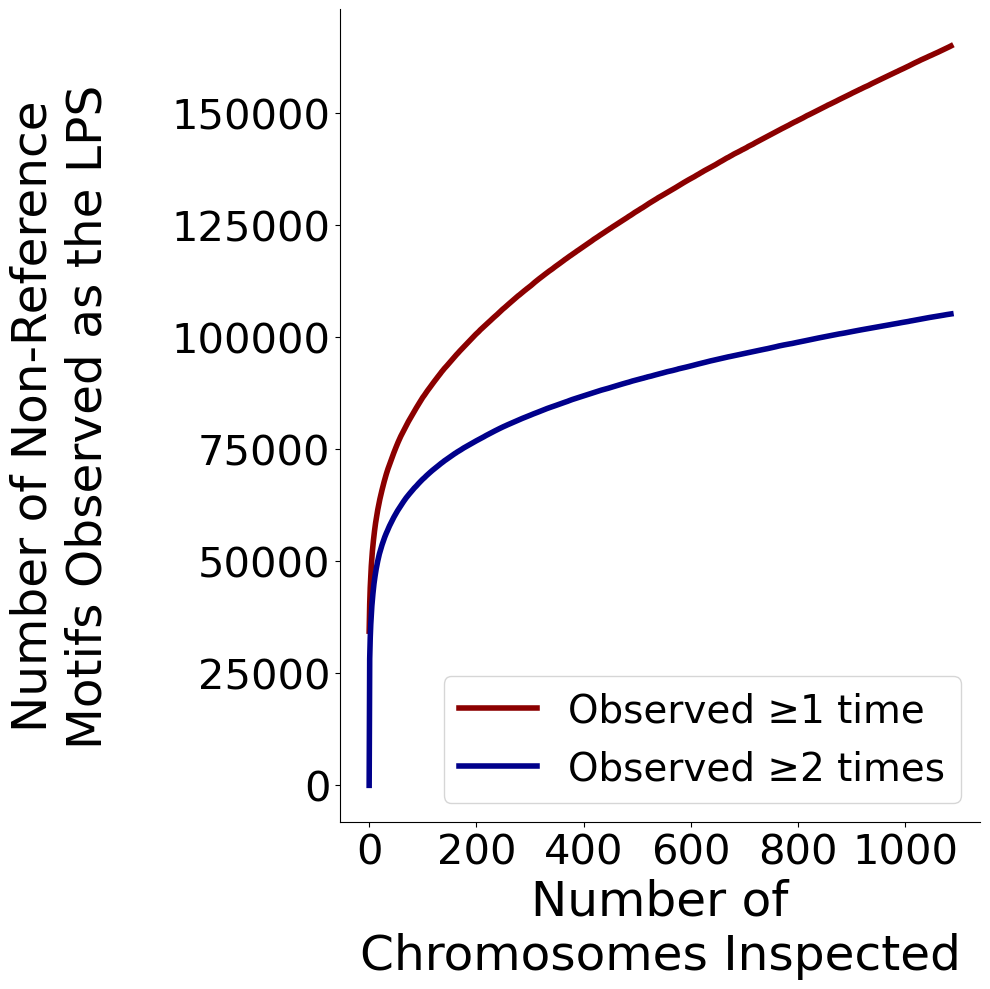

In [7]:
# plot the cumulative density curve with both "at least once" and "at least twice" curves
cumulativeNovelMotifsObservedOnce=np.cumsum(novelMotifsObservedOnce)
cumulativeNovelMotifsObservedTwice=np.cumsum(novelMotifsObservedTwice)

fig, ax = plt.subplots(figsize=(10, 10))
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'

# Plot both curves
plt.plot(cumulativeNovelMotifsObservedOnce, c="darkred", linewidth=4, label='Observed ≥1 time')
plt.plot(cumulativeNovelMotifsObservedTwice, c="darkblue", linewidth=4, label='Observed ≥2 times')

plt.ylabel('Number of Non-Reference\nMotifs Observed as the LPS\n', fontsize=35)
plt.xlabel('Number of\nChromosomes Inspected', fontsize=35)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.legend(fontsize=28, loc='lower right', frameon=True)
plt.tight_layout()
plt.savefig('figures/Figure2D.svg')
plt.savefig('figures/Figure2D.png',dpi=600)

# 2E: Novel Motifs by Locus Variation

C:\Users\Matt\AppData\Local\Temp\ipykernel_31100\1672266667.py:64: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-white')


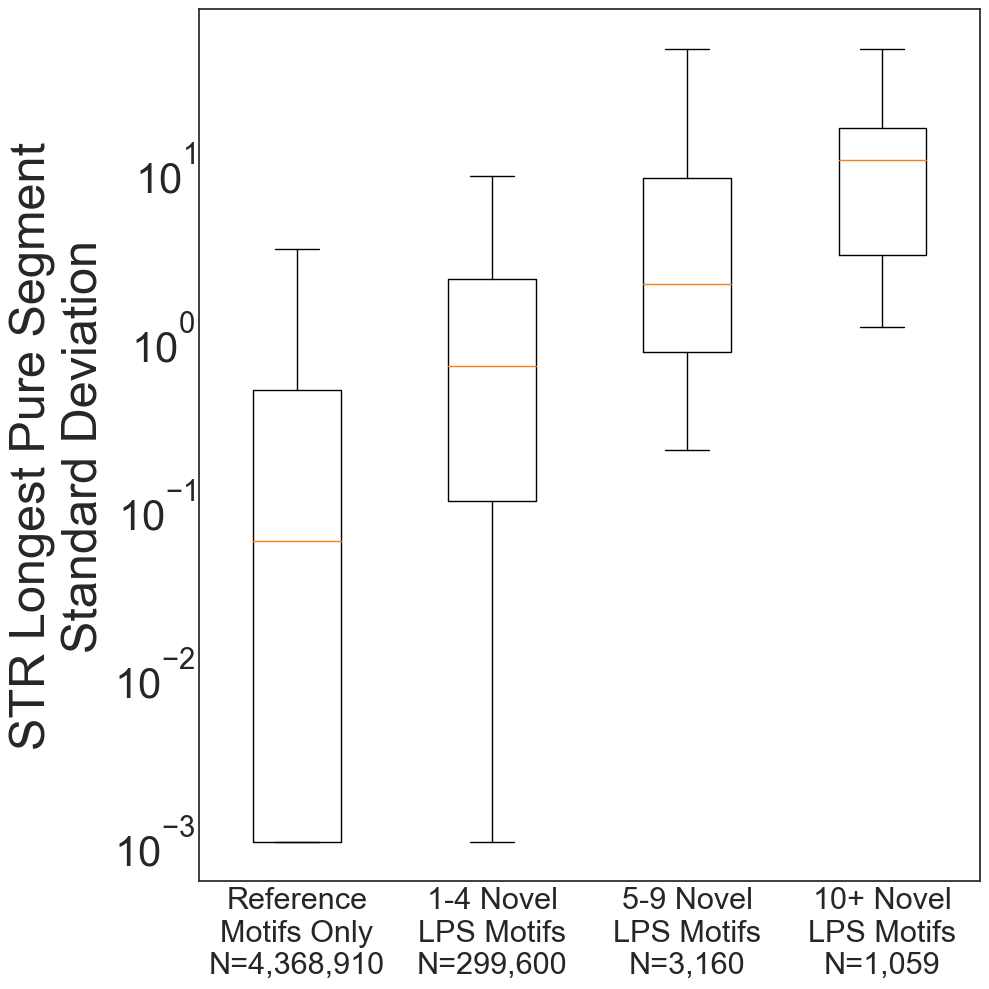

In [ ]:
# box plots of length variation as a function of motif variation
import pandas
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
discoveryCohort=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
catalog=pandas.read_csv('assets/variation_clusters_and_isolated_TRs_v1.0.1.hg38.TRGT.bed.gz',sep='\t',header=None,names=['Chrom','Start','Stop','Info'])

# groom the catalog dataframe
catalog[['TRID','MOTIFS','STRUC']]=catalog.loc[:,'Info'].str.split(';',expand=True)
catalog['TRID']=catalog.loc[:,'TRID'].str[3:]
catalog['MOTIFS']=catalog.loc[:,'MOTIFS'].str[7:].str.split(',',expand=False)
catalog['STRUC']=catalog.loc[:,'STRUC'].str[6:]
catalog=catalog.loc[:,['TRID','MOTIFS']]
catalog2=catalog.loc[catalog['TRID'].isin(discoveryCohort.loc[:,'TRID'].values),:].reset_index(drop=True)
catalog2=catalog2.loc[:,['TRID','MOTIFS']].explode('MOTIFS').reset_index(drop=True)
# function to convert motifs to their simplest rotational form
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    return(min(motifs))

# apply the simplest_motif function to both the catalog and lps dataframes
catalog2['simpleMotif']=catalog2.loc[:,'MOTIFS'].apply(simplest_motif)
discoveryCohort['simpleMotif']=discoveryCohort.loc[:,'LPS_Motif'].apply(simplest_motif)

# merge to see which motifs observed as lps are in the catalog
discoveryCohort=discoveryCohort.loc[:,['TRID','simpleMotif','N_motif','std']].merge(catalog2,how='left',on=['TRID','simpleMotif'],indicator=True)

novelMotifs=discoveryCohort.loc[discoveryCohort['_merge']=='left_only',:].reset_index(drop=True)


discoveryCohort['Stdev_mult']=discoveryCohort.loc[:,'std']*discoveryCohort.loc[:,'N_motif']
discoveryCohort2=discoveryCohort.groupby('TRID').agg(N_motif_summed=("N_motif","sum"),Stdev_summed=("Stdev_mult","sum"))
discoveryCohort2['Stdev_wm']=discoveryCohort2.loc[:,'Stdev_summed']/discoveryCohort2.loc[:,'N_motif_summed']
discoveryCohort2=discoveryCohort2.reset_index(drop=False).loc[:,['TRID','N_motif_summed','Stdev_wm']]

motifCounts=discoveryCohort.loc[:,['TRID','simpleMotif']].groupby('TRID').count().reset_index(drop=False).rename(columns={'simpleMotif':'numMotifsObserved'})
lps3=discoveryCohort.merge(motifCounts,how='inner',on='TRID')

tmp=novelMotifs.loc[:,['TRID','simpleMotif']].groupby('TRID').count().reset_index(drop=False).rename(columns={'simpleMotif':'numNovelMotifsObserved'})
lps4=lps3.merge(tmp,how='left',on='TRID')
lps4['numNovelMotifsObserved']=lps4.loc[:,'numNovelMotifsObserved'].fillna(0)
lps4['numMotifsObserved']=lps4.loc[:,'numMotifsObserved'].fillna(0)

lps4=lps4.merge(discoveryCohort2.loc[:,['TRID','Stdev_wm']],how='left',on='TRID')

# calculate n per box
group1=len(lps4.loc[lps4['numNovelMotifsObserved']==0,:])
group2=len(lps4.loc[((lps4['numNovelMotifsObserved']>0) & (lps4['numNovelMotifsObserved']<5)),:])
group3=len(lps4.loc[((lps4['numNovelMotifsObserved']>=5) & (lps4['numNovelMotifsObserved']<10)),:])
group4=len(lps4.loc[((lps4['numNovelMotifsObserved']>=10)),:])


from matplotlib import pyplot as plt
plt.style.use('seaborn-white')
plt.figure(figsize=(10, 10))
plt.boxplot([lps4.loc[lps4['numNovelMotifsObserved']==0,'Stdev_wm'].values+0.001,lps4.loc[((lps4['numNovelMotifsObserved']>0) & (lps4['numNovelMotifsObserved']<5)),'Stdev_wm'].values+0.001,
             lps4.loc[((lps4['numNovelMotifsObserved']>=5) & (lps4['numNovelMotifsObserved']<10)),'Stdev_wm'].values+0.001,
             lps4.loc[((lps4['numNovelMotifsObserved']>=10)),'Stdev_wm'].values+0.001],whis=[5,95],showfliers=False)
#plt.xlabel('Locus Length Variance',fontsize=20)
plt.xticks([1,2,3,4],[f'Reference\nMotifs Only\nN={group1:,}',f'1-4 Novel\nLPS Motifs\nN={group2:,}',f'5-9 Novel\nLPS Motifs\nN={group3:,}',f'10+ Novel\nLPS Motifs\nN={group4:,}'],fontsize=22)
plt.ylabel('STR Longest Pure Segment\nStandard Deviation',fontsize=35)
plt.yticks(fontsize=30)
#plt.title('Length Variance of Tandem Repeat Loci\nas a Function of Novel LPS Motifs',fontsize=32)
plt.yscale('log')
plt.tight_layout()
plt.savefig('figures/Figure2E.png',dpi=600)
plt.savefig('figures/Figure2E.svg')